```{contents}
:local:
:depth: 2
```

# 2.3 Duality

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 4, Lesson 6: *Duality: Mathematical Representation*
- Module 4, Lesson 7: *Duality: Graphical Representation*
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Construct the dual function and the dual problem of a constrained problem from its Lagrangian.
- Prove weak duality and explain why the dual function is always concave.
- Derive the dual of a linear program and read it as a pricing problem.
- Derive the LP and nonlinear duals of the electrolysis cell, and verify strong duality numerically.
- Interpret duality graphically, and explain why convex problems have no duality gap while non-convex problems can.
:::

In Topic 2.2 we introduced the multipliers as a device for writing down optimality conditions. In this topic we will see that the multipliers are also the variables of a second optimization problem, which is called the **dual problem**. The original problem (now called the **primal**) chooses quantities, while the dual chooses prices. Every value of the dual is a lower bound on the primal, and for convex problems the best such bound is equal to the primal optimum. This lower-bound property is what drives branch-and-bound in Topics 2.5 and 2.6.

## The dual problem

Let's start from the primal problem

$$
\text{(P)} \qquad \min_{x \in X} f(x) \quad \text{s.t.} \quad h_j(x) = b_j, \;\; j = 1, \ldots, M, \qquad g_k(x) \le 0, \;\; k = 1, \ldots, N,
$$

where $X$ collects simple bounds such as $x \ge 0$. We assume that the functions are continuous and that the problem has at least one feasible point, but we do *not* assume convexity. With the sign convention from Topic 2.2, the Lagrangian of this problem is

$$
\mathcal{L}(x, \lambda, \nu) = f(x) - \sum_j \lambda_j \left(h_j(x) - b_j\right) + \sum_k \nu_k\, g_k(x), \qquad \nu \ge 0, \;\; \lambda \text{ free}.
$$

We build the dual in two steps. First, we fix the multipliers and minimize the Lagrangian over the primal variables, which gives the **dual function**

$$
\phi(\lambda, \nu) = \min_{x \in X} \mathcal{L}(x, \lambda, \nu),
$$

which may be $-\infty$ for some multipliers (texts that allow the minimum not to be attained write $\inf$ here). Second, we choose the multipliers to make this as large as possible, which gives the **dual problem**

$$
\text{(D)} \qquad \max_{\lambda,\; \nu \ge 0} \; \phi(\lambda, \nu) .
$$

**Why maximize? Weak duality.** Pick any feasible $x$ and any multipliers with $\nu \ge 0$. At a feasible point the equality terms vanish and each $\nu_k g_k(x) \le 0$, so we know that $\mathcal{L}(x, \lambda, \nu) \le f(x)$, and since the dual function is the minimum of $\mathcal{L}$ over *all* $x \in X$, it can be no larger than $\mathcal{L}$ at this particular feasible $x$:

$$
\phi(\lambda, \nu) \;\le\; \mathcal{L}(x, \lambda, \nu) \;\le\; f(x).
$$

As a result, every dual value is a lower bound on every primal value, which is called **weak duality**, and it needs no assumptions at all. When we maximize $\phi$ we push the lower bound up as far as it will go, and the difference between the primal minimum and the dual maximum is called the **duality gap**, so when the gap is zero we say that we have **strong duality**.

**The dual function is always concave.** For each fixed $x$, $\mathcal{L}$ is a linear function of the multipliers, and the dual function is the pointwise minimum of these linear functions, which is concave. So the dual problem is a concave maximization, which is a convex problem *regardless of whether the primal is convex*, and we will use this property in Topic 2.6.

### A worked example: the dual of the ohmic dispatch

Consider the ohmic dispatch of Topics 2.1 and 2.2, where we keep the bounds $0 \le x_i \le 1$ in $X$ and dualize only the demand constraint:

$$
\phi(\lambda) = \min_{0 \le x \le 1} \left[\sum_i \left(x_i + r_i x_i^2\right) - \lambda\left(\sum_i x_i - D\right)\right] = \lambda D + \sum_i \min_{0 \le x_i \le 1}\left(x_i + r_i x_i^2 - \lambda x_i\right).
$$

When we dualize the coupling constraint, the problem splits into one small problem per stack. At a hydrogen price of $\lambda$, stack $i$ chooses its own load to maximize $\lambda x_i - P_i(x_i)$ (its value of output less its power), and the answer is $x_i(\lambda) = \mathrm{clip}\big((\lambda - 1)/2r_i,\, 0,\, 1\big)$. The dual problem is then a one-variable concave maximization over the price, which is also the structure that the bounding step of Topic 2.6 uses.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


primal minimum 1.42909 at price 1.38182
dual maximum   1.42909 at price 1.38182;  gap 1.2e-13
   q(1.0) = 1.20000  <= 1.42909  (weak duality)
   q(1.2) = 1.37714  <= 1.42909  (weak duality)
   q(1.6) = 1.35429  <= 1.42909  (weak duality)


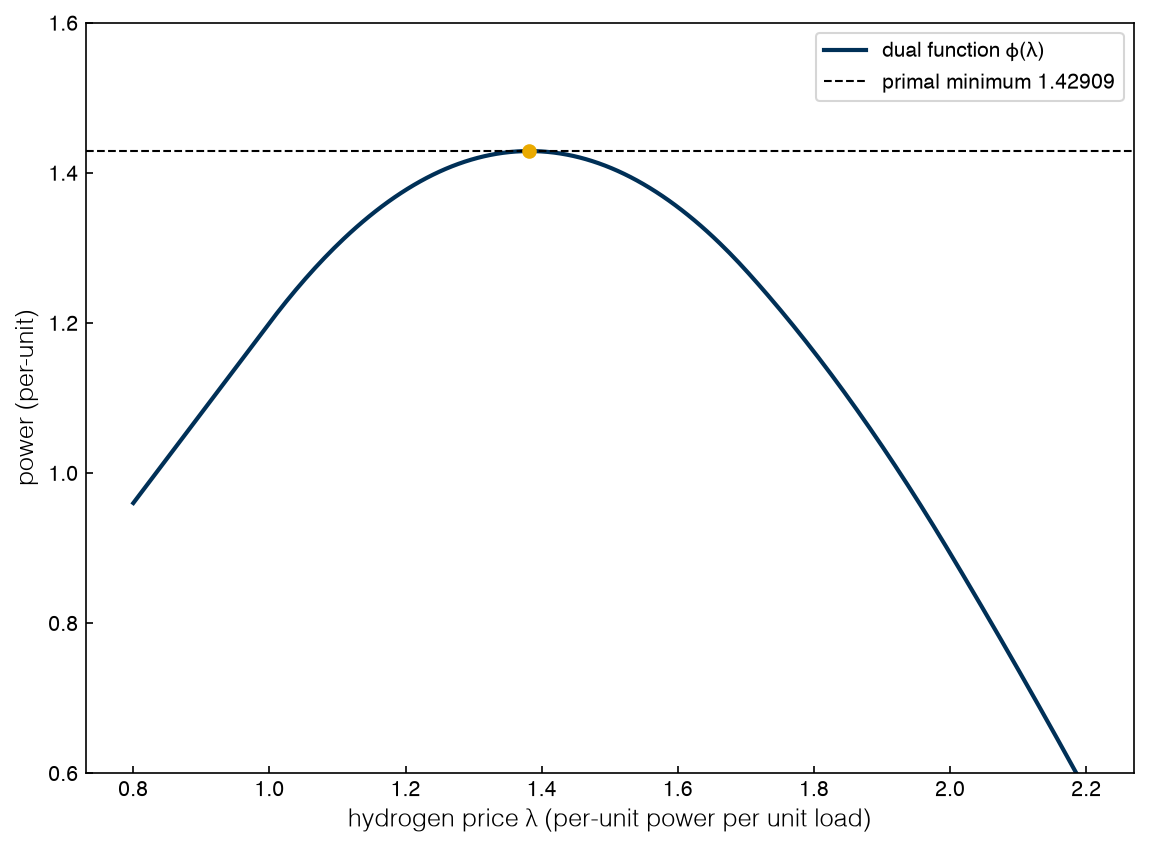

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
import pyomo.environ as pyo
from scipy.optimize import linprog, minimize_scalar
plt.style.use('../settings/plot_style.mplstyle')
from _lib import electrolyzer as el
from _lib import part2a_tools as t2

D = 1.2
lam_p, x_p, C_p, _ = t2.ohmic_dispatch(D)                         # primal optimum (Topic 2.2)
res = minimize_scalar(lambda L: -t2.ohmic_dual(L, D), bounds=(1, 3), method='bounded',
                      options={'xatol': 1e-12})
print(f"primal minimum {C_p:.5f} at price {lam_p:.5f}")
print(f"dual maximum   {-res.fun:.5f} at price {res.x:.5f};  gap {C_p + res.fun:.1e}")
for L in (1.0, 1.2, 1.6):
    print(f"   q({L}) = {t2.ohmic_dual(L, D):.5f}  <= {C_p:.5f}  (weak duality)")

lams = np.linspace(0.8, 2.2, 300)
fig, ax = plt.subplots()
ax.plot(lams, t2.ohmic_dual(lams, D), label='dual function $\\phi(\\lambda)$')
ax.axhline(C_p, color='k', ls='--', lw=1, label=f'primal minimum {C_p:.5f}')
ax.plot(lam_p, C_p, 'o', color='C1')
ax.set_xlabel('hydrogen price $\\lambda$ (per-unit power per unit load)')
ax.set_ylabel('power (per-unit)')
ax.set_ylim(0.6, 1.6); ax.legend();

The dual function is concave, every value lies below the primal minimum, and its maximum touches the primal minimum at $\phi^* = 1.42909$ and $\lambda^* = 1.38182$, which is the price we found in Topic 2.2. The duality gap is zero, as it must be for a convex problem.

:::{exercise}
:label: ex-t23-dual-by-hand

Work the dual of a one-variable problem entirely by hand: $\min_x (x - 1)^2$ subject to $2x - 1 = 0$. Form the Lagrangian with the sign convention of this book, minimize it over $x$ for fixed $\lambda$ (check that the minimum exists), write the dual function, and maximize it. Compare the dual optimum and multiplier with the primal solution, and check your $\lambda$ against $\partial f^*/\partial b$ for the constraint $2x - 1 = b$.
:::

:::{exercise}
:label: ex-t23-dual-shape

The dual function above has kinks. Find where they are and explain each one in terms of the per-stack loads $x_i(\lambda)$. (Hint: print `t2.ohmic_loads(L)` for a few prices near each kink.) Then plot $\phi(\lambda)$ for $D = 2.5$ and check that its maximum is at $\lambda = 1.875$.
:::

## Linear programming duality

For an LP we can compute the dual function by hand, and the dual turns out to be another LP. Let's take the linear dispatch of Topic 1.4, where stack $i$ costs $e_i$ per unit of load, with $e = (1.20, 1.45, 1.70)$:

$$
\min_x \sum_i e_i x_i \quad \text{s.t.} \quad \sum_i x_i = D \;\; (\lambda), \qquad x_i \le 1 \;\; (u_i \ge 0), \qquad x \ge 0 .
$$

The Lagrangian is $\sum_i e_i x_i - \lambda(\sum_i x_i - D) + \sum_i u_i (x_i - 1)$, and if we collect the terms in each $x_i$ we get

$$
\mathcal{L} = \lambda D - \sum_i u_i + \sum_i \left(e_i - \lambda + u_i\right) x_i .
$$

When we minimize over $x \ge 0$, any negative coefficient $e_i - \lambda + u_i$ lets us send $x_i \to \infty$ and $\mathcal{L}$ to $-\infty$, but otherwise the minimum is at $x = 0$ and is equal to $\lambda D - \sum_i u_i$. The dual function is therefore finite exactly when every coefficient is nonnegative, so the dual problem is

$$
\max_{\lambda,\; u \ge 0} \; \lambda D - \sum_i u_i \quad \text{s.t.} \quad \lambda - u_i \le e_i \quad \text{for each stack } i.
$$

Notice that the roles have been transposed in the dual. Each primal constraint has become a dual variable ($\lambda$ for demand and $u_i$ for capacity), and each primal variable has become a dual constraint (one per stack). In the same way, the right-hand sides of the primal ($D$ and the capacities) have become the objective coefficients of the dual, while the costs in the primal have become the right-hand sides of the dual.

**The broker.** We can read this pair as two people who are bargaining over the same plant. The factory minimizes cost over quantities; the broker maximizes appraisal over prices. The broker posts a price $\lambda$ for hydrogen and a rent $u_i$ for the capacity of each stack, and appraises the order at $\lambda D$ less the rents that are paid out. The prices of the broker must not leave the factory an arbitrage, so for every stack the value of a unit of its hydrogen must not exceed what that unit costs to make, which is its operating cost plus its capacity rent, $\lambda \le e_i + u_i$. Weak duality says that the appraisal never exceeds the cost of any feasible dispatch, and strong duality (which always holds for a feasible, bounded LP) says that at the optimum the two agree and the books balance.

We solve both problems with HiGHS:

In [2]:
e = np.array([el.E_LINEAR[c] for c in el.NAMES])
primal = linprog(e, A_eq=[np.ones(3)], b_eq=[D], bounds=[(0, 1)] * 3, method='highs')
# dual variables (lambda, u_A, u_B, u_C); linprog minimizes, so negate the objective
A_ub = np.hstack([np.ones((3, 1)), -np.eye(3)])                  # lambda - u_i <= e_i
dual = linprog([-D, 1, 1, 1], A_ub=A_ub, b_ub=e,
               bounds=[(None, None)] + [(0, None)] * 3, method='highs')
lam_lp, u = dual.x[0], dual.x[1:]
print(f"primal: loads {np.round(primal.x, 3)}, cost {primal.fun:.3f}")
print(f"dual:   price {lam_lp:.3f}, rents {np.round(u, 3)}, appraisal {-dual.fun:.3f}")
print(f"solver's own demand multiplier: {primal.eqlin.marginals[0]:.3f}")
print(f"reduced costs e_i - lambda + u_i: {np.round(e - lam_lp + u, 3)}")
print(f"hydrogen price {lam_lp:.2f} per-unit = {lam_lp * el.DG0 / 1e3:.0f} kJ/mol "
      f"= {lam_lp * el.E0:.2f} V-equivalent = {lam_lp * el.DG0 / 2.01588 / 3600:.1f} kWh/kg")

primal: loads [1.  0.2 0. ], cost 1.490
dual:   price 1.450, rents [0.25 0.   0.  ], appraisal 1.490
solver's own demand multiplier: 1.450
reduced costs e_i - lambda + u_i: [0.   0.   0.25]
hydrogen price 1.45 per-unit = 344 kJ/mol = 1.78 V-equivalent = 47.4 kWh/kg


Both problems give 1.490. Stack A runs at full load, B takes the remaining 0.2, and C is idle. The dual price of hydrogen is 1.45, which is the cost of the stack that is running at part load, and the solver reports the same number as the demand multiplier of the primal. Stack A earns a capacity rent of $1.45 - 1.20 = 0.25$, while stack C has a reduced cost of $1.70 - 1.45 = 0.25$, so it is priced out. Complementary slackness links the two solutions term by term, since the full stack has a positive rent, the part-loaded stack has a zero rent and zero reduced cost, and the idle stack has a positive reduced cost.

**Two multipliers for a mole of hydrogen.** The kernel and the fleet each put a value on a mole of hydrogen, so it is worth comparing them once. In the kernel of Topic 2.2, the marginal free energy of a mole of H₂ supplied by the electrons is $2FU$, which at the reversible voltage is $2FE^0 = 237$ kJ/mol (or one per-unit). The demand multiplier of the fleet is the marginal energy per mole of H₂ in the real stacks, which is 1.45 per-unit (344 kJ/mol) in this linear model and 1.38182 per-unit (328 kJ/mol) with ohmic losses. If we divide each of these by $2F$ we get a voltage, so the marginal stack behaves like a cell at 1.78 V or 1.70 V, compared with the reversible 1.229 V. The demand multiplier is thus a marginal effective voltage, and the gap between it and the reversible voltage is the loss.

In market terms the same comparison reads differently, since the multiplier is what the next kilogram costs the plant (47.4 kWh/kg here) while the ideal cell would need 32.7 kWh/kg, and the difference is the price that the plant pays for the inefficiency of the stacks.

### The dual of the electrolysis LP

Next we derive the dual of the electrolysis cell in its LP limit from Topic 1.2, where the gases are drawn off at a pressure of 1 bar, and if we work per mole of water fed the primal is

$$
\min_{n, q \ge 0} \; -\Delta G^0 n_{\mathrm{H_2O}} - FUq \quad \text{s.t.} \quad
\begin{cases}
2 n_{\mathrm{H_2O}} + 2 n_{\mathrm{H_2}} = 2 & (\lambda_{\mathrm{H}}) \\
n_{\mathrm{H_2O}} + 2 n_{\mathrm{O_2}} = 1 & (\lambda_{\mathrm{O}}) \\
q - 2 n_{\mathrm{H_2}} = 0 & (\lambda_e)
\end{cases}
$$

If we follow the same steps as above, we get one dual constraint per primal variable:

$$
\max_{\lambda} \; 2\lambda_{\mathrm{H}} + \lambda_{\mathrm{O}} \quad \text{s.t.} \quad
\underbrace{2\lambda_{\mathrm{H}} + \lambda_{\mathrm{O}} \le -\Delta G^0}_{\mathrm{H_2O}}, \quad
\underbrace{2\lambda_{\mathrm{H}} - 2\lambda_e \le 0}_{\mathrm{H_2}}, \quad
\underbrace{2\lambda_{\mathrm{O}} \le 0}_{\mathrm{O_2}}, \quad
\underbrace{\lambda_e \le -FU}_{q}.
$$

Each of these constraints says that a species can be worth no more than its parts, so the dual constraints are just the Lagrange identities of Topic 2.2 turned into inequalities. Since the charge balance has a zero right-hand side, $\lambda_e$ does not appear in the objective, and the H₂ and $q$ constraints together say only that $\lambda_{\mathrm{H}} \le \lambda_e \le -FU$ (i.e. $\lambda_{\mathrm{H}} \le -FU$). This means that the dual lives in the plane of the two atom prices, with three edges that correspond to water, oxygen, and hydrogen-plus-electrons. The primal had four variables and three constraints, while the dual has three variables (of which only two matter), so the primal and dual live in different spaces that are linked by the same matrix read by rows and by columns.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


U = E0 -0.05 V: primal -237.13 kJ (n = [ 1.  0. -0. -0.]), dual -237.13 kJ, solver's dual point (lam_H, lam_O) = (-118.56, -0.00) kJ/mol
U = E0 +0.05 V: primal -246.78 kJ (n = [0.  1.  0.5 2. ]), dual -246.78 kJ, solver's dual point (lam_H, lam_O) = (-123.39, -0.00) kJ/mol


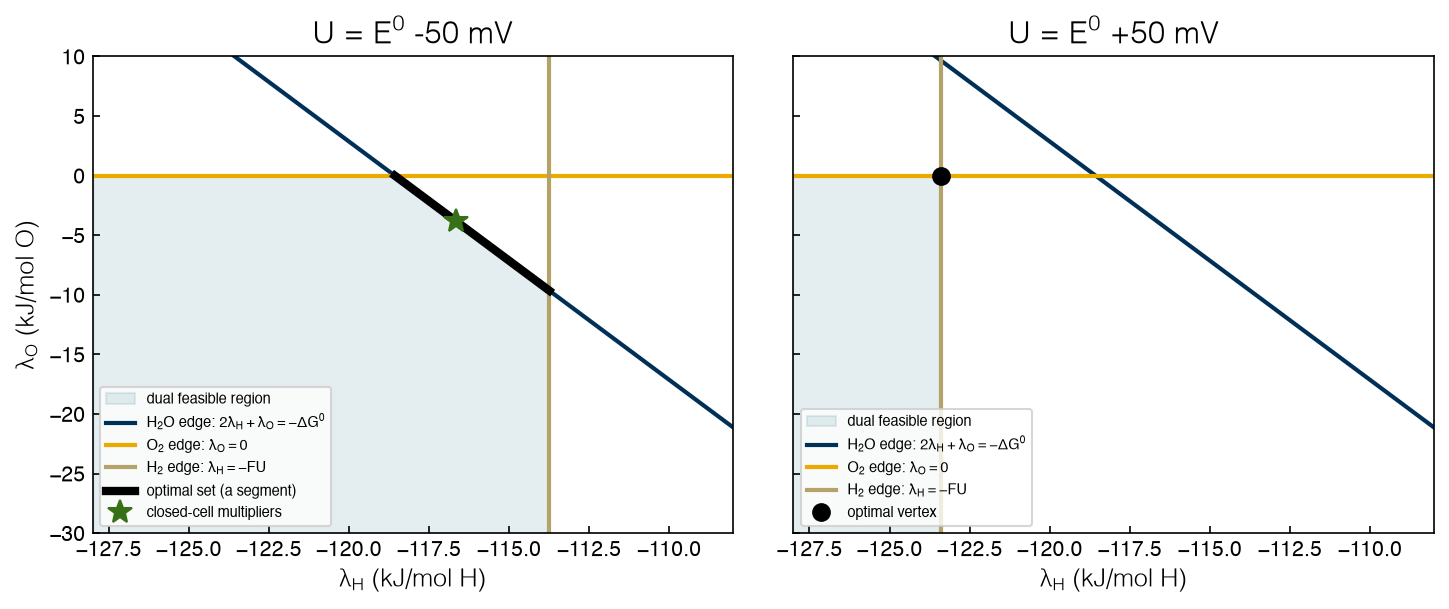

In [3]:
F, DG0, E0 = t2.F, t2.DG0, t2.E0
A = np.array([[2, 2, 0, 0], [1, 0, 2, 0], [0, -2, 0, 1]])          # rows H, O, charge; cols H2O, H2, O2, q
b = np.array([2, 1, 0])

def kernel_lp_pair(U):
    c = np.array([-DG0, 0, 0, -F * U])
    p = linprog(c, A_eq=A, b_eq=b, bounds=[(0, None)] * 4, method='highs')
    d = linprog(-b, A_ub=A.T, b_ub=c, bounds=[(None, None)] * 3, method='highs')
    return p, d

nlp_mult = t2.kernel_closed_form(E0 - 0.05)[2:]                       # closed-cell multipliers (Topic 2.2)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
LH = np.linspace(-128, -108, 400)
for ax, dU in zip(axes, (-0.05, 0.05)):
    U = E0 + dU
    p, d = kernel_lp_pair(U)
    print(f"U = E0 {dU:+.2f} V: primal {p.fun/1e3:.2f} kJ (n = {np.round(p.x, 3)}), dual {-d.fun/1e3:.2f} kJ, "
          f"solver's dual point (lam_H, lam_O) = ({d.x[0]/1e3:.2f}, {d.x[1]/1e3:.2f}) kJ/mol")
    water = (-DG0 - 2 * LH * 1e3) / 1e3
    top = np.minimum(water, 0.0)
    ax.fill_between(LH[LH <= -F * U / 1e3], -30, top[LH <= -F * U / 1e3], color='C2', alpha=0.15,
                    label='dual feasible region')
    ax.plot(LH, water, 'C0', label='H$_2$O edge: $2\\lambda_H + \\lambda_O = -\\Delta G^0$')
    ax.axhline(0, color='C1', label='O$_2$ edge: $\\lambda_O = 0$')
    ax.axvline(-F * U / 1e3, color='C3', label='H$_2$ edge: $\\lambda_H = -FU$')
    if dU < 0:
        seg = np.array([-DG0 / 2, -F * U]) / 1e3
        ax.plot(seg, (-DG0 - 2 * seg * 1e3) / 1e3, 'k', lw=4, label='optimal set (a segment)')
        ax.plot(nlp_mult[0] / 1e3, nlp_mult[1] / 1e3, '*', color='C4', ms=12, label='closed-cell multipliers')
    else:
        ax.plot(-F * U / 1e3, 0, 'ko', ms=8, label='optimal vertex')
    ax.set_xlim(-128, -108); ax.set_ylim(-30, 10)
    ax.set_title(f'U = E$^0$ {dU*1e3:+.0f} mV')
    ax.set_xlabel('$\\lambda_H$ (kJ/mol H)')
axes[0].set_ylabel('$\\lambda_O$ (kJ/mol O)')
axes[0].legend(fontsize=7, loc='lower left'); axes[1].legend(fontsize=7, loc='lower left')
plt.tight_layout();

Below the reversible voltage (left) the primal keeps all of the water, and the dual objective $2\lambda_{\mathrm{H}} + \lambda_{\mathrm{O}}$ is parallel to the water edge. Every point on the edge between the oxygen edge and the hydrogen edge is optimal, with a value of $-237.13$ kJ, so the dual optimum is a whole segment rather than a single point. This happens because the primal vertex is **degenerate**, since six constraints are active (the three balances and the three bounds $n_{\mathrm{H_2}} = n_{\mathrm{O_2}} = q = 0$) in a four-dimensional space, which is two more than a vertex needs, and degenerate primals have non-unique duals. Only the price of water, $2\lambda_{\mathrm{H}} + \lambda_{\mathrm{O}}$, is pinned, and how that price splits between H and O is not, because no H₂ or O₂ is made that would reveal it. HiGHS returns one end of the segment, $(-118.565, 0)$, but another solver could return any other point, so we need to keep this in mind when we interpret shadow prices from a degenerate LP.

Above the reversible voltage (right) the hydrogen edge has moved past the corner where the water and oxygen edges meet. Now the optimum is a single vertex, $\lambda_{\mathrm{H}} = -FU$, $\lambda_{\mathrm{O}} = 0$, with a value of $-2FU = -246.78$ kJ, which is equal to the primal value with all of the water split. As $U$ rises through $E^0$ the optimal set shrinks from a segment to a point, and this happens at the same voltage where the primal jumps from one vertex to the other.

The star on the left marks the multipliers of the closed cell at the same voltage, which we found in Topic 2.2. It sits on the water edge, inside the optimal segment of the LP, and we will explain why in the next section.

:::{exercise}
:label: ex-t23-dual-price

Repeat the dual-plane plot at $U = E^0 - 0.10$ V and $U = E^0 - 0.01$ V. How does the length of the optimal segment depend on $U$? Derive the length in kJ/mol from the edge equations and compare.
:::

## The nonlinear dual of the electrolysis cell

Now let's dualize the closed cell of Topic 2.2, where the gases stay in a 1 L headspace. We keep $n \ge 0$ and $q \ge 0$ in $X$ and dualize the three balances, and since the Lagrangian separates by variable, the dual function is a sum of one-variable minimizations:

- **The charge $q$** enters linearly with coefficient $-FU - \lambda_e$. The minimum over $q \ge 0$ is 0 if $\lambda_e \le -FU$ and $-\infty$ otherwise.
- **The liquid water** enters linearly with coefficient $-\Delta G^0 - 2\lambda_{\mathrm{H}} - \lambda_{\mathrm{O}}$. The minimum is 0 if $2\lambda_{\mathrm{H}} + \lambda_{\mathrm{O}} \le -\Delta G^0$ and $-\infty$ otherwise. These are the same two edges as in the LP.
- **Each gas** enters through $n\left[RT\left(\ln(p/p^0) - 1\right)\right] - a\,n$, where $a = 2\lambda_{\mathrm{H}} - 2\lambda_e$ for H₂ and $a = 2\lambda_{\mathrm{O}}$ for O₂. Setting the derivative to zero gives $RT \ln(p/p^0) = a$, a gas whose chemical potential equals the price of its parts, and substituting back, the minimum is $-p^0 V e^{a/RT}$, which is $-pV$ for that gas.

Summing the pieces, the dual function is

$$
\phi(\lambda) = \lambda_{\mathrm{H}} b_{\mathrm{H}} + \lambda_{\mathrm{O}} b_{\mathrm{O}} - p^0 V \left[e^{2(\lambda_{\mathrm{H}} - \lambda_e)/RT} + e^{2\lambda_{\mathrm{O}}/RT}\right]
\quad \text{on} \quad \lambda_e \le -FU, \;\; 2\lambda_{\mathrm{H}} + \lambda_{\mathrm{O}} \le -\Delta G^0 .
$$

The hard oxygen and hydrogen edges of the LP have become smooth exponential penalties. Well inside an edge the penalty is negligible, and beyond it the penalty grows exponentially over a width of order $RT/2 \approx 1.2$ kJ/mol, so two edges of the LP polygon have been softened by an amount that is set by $RT$.

Two of the remaining choices are easy. The dual function increases with $\lambda_e$, so at the optimum $\lambda_e = -FU$, which means that the electron price is pinned by the power supply. With water in excess the water edge is active, so $\lambda_{\mathrm{H}} = (-\Delta G^0 - \lambda_{\mathrm{O}})/2$ and the dual becomes a one-variable concave maximization over $\lambda_{\mathrm{O}}$, which we can solve and compare with the primal solution from Ipopt:

In [4]:
R, T, P0, V, NW = t2.R, t2.T, t2.P0, t2.V_HEAD, t2.N_WATER
bH, bO = 2 * NW, NW

def q_dual(lam_O, U):
    lam_H = (-DG0 - lam_O) / 2                                     # on the water edge
    lam_e = -F * U                                                 # pinned by the power supply
    return (lam_H * bH + lam_O * bO
            - P0 * V * (np.exp(2 * (lam_H - lam_e) / (R * T)) + np.exp(2 * lam_O / (R * T))))

ipopt = t2.get_solver('ipopt')
for dU in (-0.05, 0.0, 0.05):
    U = E0 + dU
    best = minimize_scalar(lambda z: -q_dual(z, U), bounds=(-30e3, 30e3), method='bounded',
                           options={'xatol': 1e-9})
    lam_O = best.x; lam_H = (-DG0 - lam_O) / 2
    if ipopt is not None:
        m = t2.kernel_nlp(U, solver=ipopt)
        G_star, lH_ip, lO_ip = pyo.value(m.obj), m.dual[m.H], m.dual[m.O]
    else:
        nh, no, lH_ip, lO_ip = t2.kernel_closed_form(U)
        G_star = float('nan'); print("(Ipopt not available: primal value not computed)")
    pV = best.fun - NW * DG0              # minus the penalty term at the optimum
    print(f"U = E0 {dU:+.2f} V: primal G* = {G_star:.3f} J, dual max = {-best.fun:.3f} J, gap {G_star + best.fun:.1e} J")
    print(f"     dual (lam_H, lam_O) = ({lam_H/1e3:.3f}, {lam_O/1e3:.3f}) kJ/mol; "
          f"Ipopt ({lH_ip/1e3:.3f}, {lO_ip/1e3:.3f});  pV of the headspace = {pV:.1f} J")

U = E0 -0.05 V: primal G* = -237130014.110 J, dual max = -237130014.110 J, gap -6.0e-08 J
     dual (lam_H, lam_O) = (-116.671, -3.789) kJ/mol; Ipopt (-116.671, -3.789);  pV of the headspace = 14.1 J


U = E0 +0.00 V: primal G* = -237130188.988 J, dual max = -237130188.988 J, gap -3.0e-08 J
     dual (lam_H, lam_O) = (-118.279, -0.573) kJ/mol; Ipopt (-118.279, -0.573);  pV of the headspace = 189.0 J


U = E0 +0.05 V: primal G* = -237132531.247 J, dual max = -237132531.247 J, gap -3.0e-08 J
     dual (lam_H, lam_O) = (-119.887, 2.643) kJ/mol; Ipopt (-119.887, 2.643);  pV of the headspace = 2531.2 J


The dual maximum is equal to the primal minimum to within the tolerances of the solvers at every voltage (the residual is below $10^{-7}$ J on an objective of $2.4 \times 10^{8}$ J), and the maximizing prices are the multipliers from Ipopt, which shows that strong duality holds for the closed cell as it should for a convex problem.

The penalty term also has a physical meaning. At the optimum the exponentials are the partial pressures in bar, so the dual objective is $\lambda \cdot b - pV$, where $pV$ is the pressure-volume product of the gas in the headspace, which is 14 J below $E^0$, 189 J at $E^0$ and 2531 J at $E^0 + 0.05$ V. Strictly speaking, the gas term of our objective is a Helmholtz energy, $\sum_i n_i\mu_i - pV$, because the headspace has a fixed volume, and strong duality is then Euler's relation for that energy with the elemental potentials pricing the atoms.

If we want to see the softened edges, we can plot the dual objective at $U = E^0 - 0.05$ V along the water edge, where both the LP dual and the nonlinear dual have their optima, and we subtract the common term $-N_{\mathrm{w}}\Delta G^0$ so that the optimal value of the LP is zero:

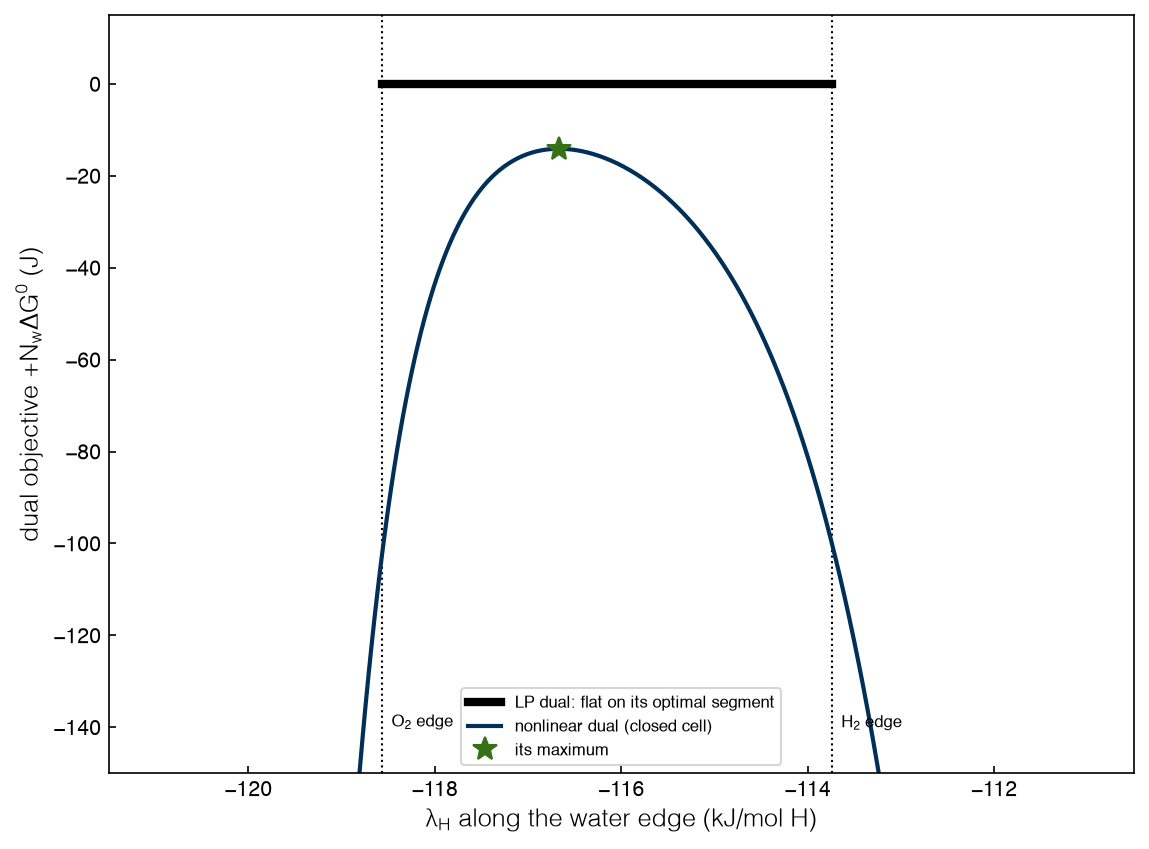

In [5]:
U = E0 - 0.05
lamH = np.linspace(-121, -111, 600) * 1e3
lamO = -DG0 - 2 * lamH
q_nl = q_dual(lamO, U) - NW * (-DG0)
lo, hi = -DG0 / 2, -F * U                                          # the LP's optimal segment

fig, ax = plt.subplots()
ax.plot([lo / 1e3, hi / 1e3], [0, 0], 'k', lw=4, label='LP dual: flat on its optimal segment')
for xv in (lo, hi):
    ax.axvline(xv / 1e3, color='k', ls=':', lw=1)
ax.plot(lamH / 1e3, q_nl, 'C0', label='nonlinear dual (closed cell)')
ax.plot(nlp_mult[0] / 1e3, q_dual(nlp_mult[1], U) - NW * (-DG0), '*', color='C4', ms=12,
        label='its maximum')
ax.set_ylim(-150, 15)
ax.set_xlabel('$\\lambda_H$ along the water edge (kJ/mol H)')
ax.set_ylabel('dual objective $+ N_w \\Delta G^0$ (J)')
ax.text(lo / 1e3 + 0.1, -140, 'O$_2$ edge', fontsize=8); ax.text(hi / 1e3 + 0.1, -140, 'H$_2$ edge', fontsize=8)
ax.legend(fontsize=8, loc='lower center');

The LP dual is flat across its optimal segment and drops to $-\infty$ at each end, while the nonlinear dual is a smooth hump whose hard ends have become exponential walls and whose single top lies inside the segment. In effect, the entropy of the gases acts as a selection rule among the non-unique prices of the LP, and it picks the point where the penalties of the two walls (the pressures of hydrogen and oxygen) balance at the ratio in which the electrolysis produces them, 2 : 1.

:::{exercise}
:label: ex-t23-headspace-dual

Change the headspace volume $V$ in `q_dual` to 0.1 L and to 10 L and redraw the hump. Does the location of its maximum move? Does its height? Explain both answers from the formula for $\phi(\lambda)$.
:::

## Duality as a picture

The lectures draw duality in a plane where the axes are the constraint value and the objective, and each choice of $x$ is mapped to the point $(\text{constraint}, \text{objective})$. For the dispatch, we take the horizontal axis to be the total load $Q = \sum_i x_i$ and the vertical axis to be the total power. The lower boundary of this cloud of points is the **value function** $v(Q)$, which is the cheapest way to make $Q$.

For a fixed price $\lambda$, the Lagrangian $f - \lambda(Q - D)$ is constant along lines of slope $\lambda$ in this plane. Minimizing the Lagrangian means that we slide such a line upward until it first touches the cloud, and the dual function $\phi(\lambda)$ is the height of that supporting line at $Q = D$. Maximizing over $\lambda$ means that we tilt the line until its height at $D$ is as large as possible. When $v$ is convex the best line is the tangent at $D$, and its height is equal to $v(D)$, which is strong duality, with the price $\lambda^*$ as the slope of the value function. However, when $v$ is not convex no supporting line can reach up into a dent, so the best dual value falls short of $v(D)$ and there is a **duality gap**.

The lectures also draw the same picture for an *inequality* constraint $g(x) \le 0$. In this case we put the constraint value $y = g(x)$ on the horizontal axis and the objective $z = f(x)$ on the vertical axis, and the primal asks for the lowest point of the set $G = \{(g(x), f(x))\}$ in the half-plane $y \le 0$. For a multiplier $\mu \ge 0$ the Lagrangian $z + \mu y$ is constant along lines of slope $-\mu$, and the dual function is the intercept at $y = 0$ of the lowest such line that still touches $G$. The dual problem then tilts the line (i.e. chooses $\mu \ge 0$) to raise that intercept as high as it can go. There are only two differences from the equality case: the sign of the slope, which comes from our sign convention, and the requirement that $\mu \ge 0$, because a line that slopes the other way would reward violating the constraint. If the constraint is inactive at the optimum then the best line is horizontal ($\mu = 0$), and this is just complementary slackness drawn as a picture.

We can draw both of these cases for the ohmic fleet at $D = 1.2$ and for two S-curve stacks of type A at $D = 0.9$, which is the non-convex problem from Topic 1.1:

S-curve, D = 0.9: primal minimum 1.58921 (one stack at 0.9), dual maximum 1.57464 at price 1.750; gap 0.01457 (0.9%)


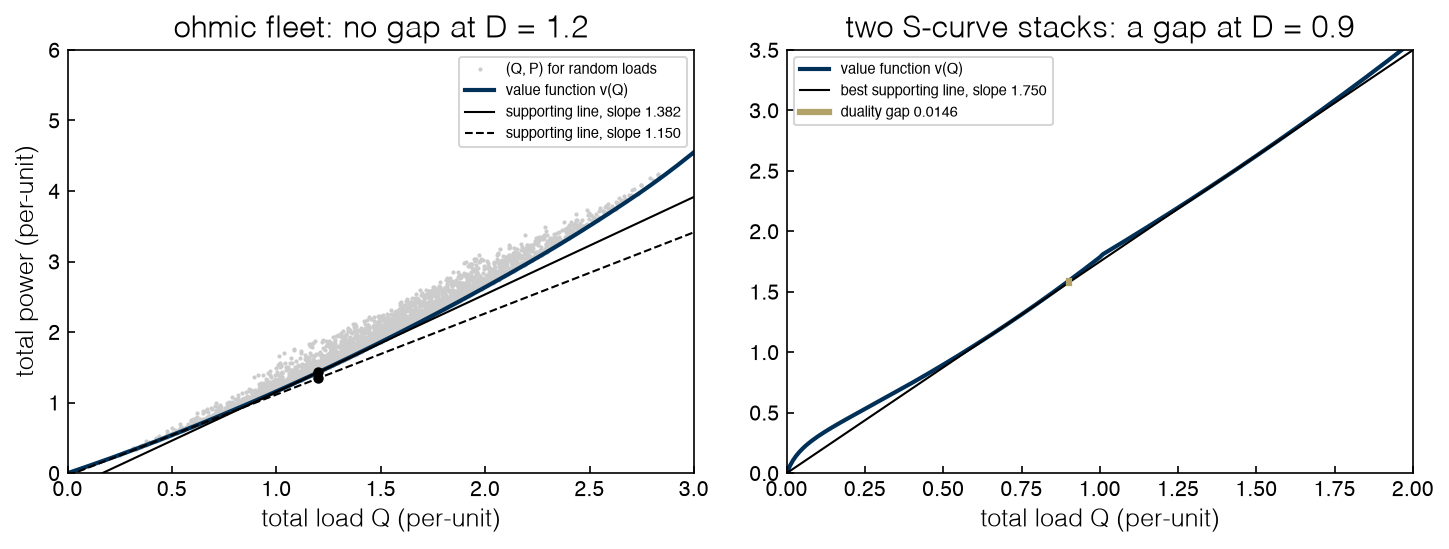

In [6]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# convex case: the ohmic fleet
X = rng.uniform(0, 1, size=(3000, 3))
rv = np.array([el.R_OHMIC[c] for c in el.NAMES])
ax = axes[0]
ax.plot(X.sum(1), np.sum(X + rv * X**2, 1), '.', color='0.8', ms=2, label='$(Q, P)$ for random loads')
Qs = np.linspace(0, 3, 200)
ax.plot(Qs, [t2.ohmic_dispatch(qq)[2] for qq in Qs], 'C0', label='value function $v(Q)$')
for L, sty in ((lam_p, '-'), (1.15, '--')):
    qL = t2.ohmic_dual(L, D)
    ax.plot(Qs, qL + L * (Qs - D), 'k', ls=sty, lw=1, label=f'supporting line, slope {L:.3f}')
    ax.plot(D, qL, 'ko', ms=4)
ax.set_xlim(0, 3); ax.set_ylim(0, 6)
ax.set_title(f'ohmic fleet: no gap at D = {D}')
ax.set_xlabel('total load $Q$ (per-unit)'); ax.set_ylabel('total power (per-unit)')
ax.legend(fontsize=7)

# non-convex case: two A stacks with the S-curve
D1 = 0.9
xg = np.linspace(0, 1, 20001)
Pg = el.p_scurve(xg, 'A')
def q_s(L):                                     # dual function: lambda D + 2 min_x (P(x) - lambda x)
    return L * D1 + 2 * np.min(Pg - L * xg)
best = minimize_scalar(lambda L: -q_s(L), bounds=(0.5, 4), method='bounded', options={'xatol': 1e-10})
lam_s, q_star = best.x, -best.fun
Qs1 = np.linspace(0, 2, 201)
def v_scurve(Q):                                # cheapest split of Q between the two stacks
    x1 = xg[(xg >= Q - 1) & (xg <= Q)]
    return np.min(el.p_scurve(x1, 'A') + el.p_scurve(Q - x1, 'A'))
v1 = [v_scurve(qq) for qq in Qs1]
v_D = v_scurve(D1)
ax = axes[1]
ax.plot(Qs1, v1, 'C0', label='value function $v(Q)$')
ax.plot(Qs1, q_star + lam_s * (Qs1 - D1), 'k', lw=1, label=f'best supporting line, slope {lam_s:.3f}')
ax.plot([D1, D1], [q_star, v_D], 'C3', lw=3, label=f'duality gap {v_D - q_star:.4f}')
ax.set_xlim(0, 2); ax.set_ylim(0, 3.5)
ax.set_title(f'two S-curve stacks: a gap at D = {D1}')
ax.set_xlabel('total load $Q$ (per-unit)')
ax.legend(fontsize=7)
plt.tight_layout()
print(f"S-curve, D = {D1}: primal minimum {v_D:.5f} (one stack at 0.9), dual maximum {q_star:.5f} "
      f"at price {lam_s:.3f}; gap {v_D - q_star:.5f} ({100 * (v_D - q_star) / v_D:.1f}%)")

On the left, the tangent line at $D = 1.2$ has a slope of 1.38182 and touches the value function, so the dual reaches the primal. The dashed line has a lower price, so it touches the cloud at a smaller load and its height at $D$ is a weaker lower bound. The right panel is different. Here the value function of the two S-curve stacks has a dent around $D = 0.9$, where running one stack alone beats any smooth split, and the best supporting line has to span the dent, so the dual maximum is 1.57464 at a price of 1.750, which is below the true minimum of 1.58921 by 0.01457 (0.9%).

In summary, the dual of a primal minimization has these properties:

- **Always:** the dual is a concave maximization, and its value is a lower bound on the primal (weak duality).
- **Convex primal** (with a strictly feasible point): the bound is tight (strong duality), and the dual's maximizers are the KKT multipliers. LPs are the special case in which the dual is again an LP.
- **Non-convex primal:** the bound may be strictly below the primal optimum. It is still a valid bound, which is what branch-and-bound needs: in Topic 2.6 the bounds come from convex relaxations, which have no gap themselves.

### The ceiling meets the floor

Weak duality gives us a way to measure progress toward the optimum without knowing what it is. Any feasible dispatch is a **ceiling**, since the optimum can be no more expensive, and any price gives a **floor**, since the optimum can be no cheaper. A simple dual method is to raise the price when the preferred loads of the stacks fall short of the demand and lower it when they overshoot, $\lambda_{k+1} = \lambda_k + \alpha\,(D - \sum_i x_i(\lambda_k))$, and at each step we can also repair the preferred loads into a feasible dispatch by sharing the shortfall equally, which gives us a ceiling.

after 25 steps: floor 1.42909, ceiling 1.42909, gap 3.4e-09, price 1.38179
gap after 1, 5, 10, 20 steps: ['2.5e-01', '1.2e-02', '2.8e-04', '1.5e-07']


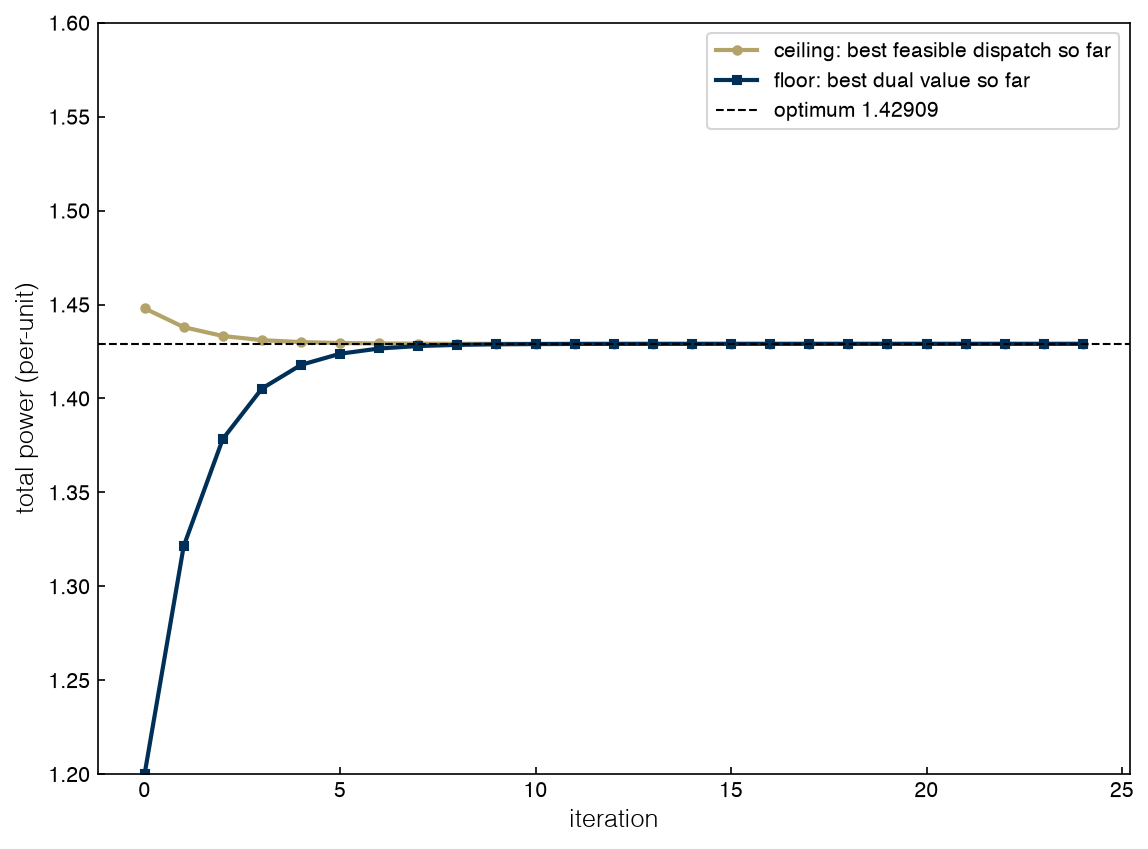

In [7]:
lam, alpha = 1.0, 0.1
floors, ceilings = [], []
best_ceiling = np.inf
for k in range(25):
    xk = t2.ohmic_loads(lam)
    floors.append(t2.ohmic_dual(lam, D))
    xf = np.clip(xk + (D - xk.sum()) / 3, 0, 1)                   # repair to a feasible dispatch
    if abs(xf.sum() - D) < 1e-12:
        best_ceiling = min(best_ceiling, np.sum(xf + rv * xf**2))
    ceilings.append(best_ceiling)
    lam += alpha * (D - xk.sum())
floors = np.maximum.accumulate(floors)
print(f"after 25 steps: floor {floors[-1]:.5f}, ceiling {ceilings[-1]:.5f}, gap {ceilings[-1] - floors[-1]:.1e}, "
      f"price {lam:.5f}")
gaps = np.array(ceilings) - floors
print("gap after 1, 5, 10, 20 steps:", [f"{gaps[k]:.1e}" for k in (0, 4, 9, 19)])

fig, ax = plt.subplots()
ax.plot(ceilings, 'C3o-', ms=4, label='ceiling: best feasible dispatch so far')
ax.plot(floors, 'C0s-', ms=4, label='floor: best dual value so far')
ax.axhline(C_p, color='k', ls='--', lw=1, label=f'optimum {C_p:.5f}')
ax.set_xlabel('iteration'); ax.set_ylabel('total power (per-unit)')
ax.set_ylim(1.2, 1.6); ax.legend();

The floor rises and the ceiling falls until they meet at 1.42909; the gap between them is 0.012 after 5 steps, $3 \times 10^{-4}$ after 10 and $10^{-7}$ after 20. At every iteration the distance between them bounds how far the best dispatch found so far can be from the optimum, a certificate that needs no knowledge of the answer. Branch-and-bound (Topic 2.5) runs on the same pair of bounds: relaxations supply floors, feasible points supply ceilings, and the search stops when they meet.

Duality returns later in the book. In Topic 3.5, the LASSO is written through its Lagrangian, which turns a constrained fit into a penalized one, and support vector regression is solved through its dual. In Topic 4.4 ({doc}`../4-data_driven_modeling/Topic4.4-Physics-Informed_Machine_Learning`), physics-informed training is posed as a constrained learning problem and trained by the same kind of dual ascent as above, with a Lagrange multiplier on the physical constraint taking the place of a hand-tuned penalty weight.

:::{exercise}
:label: ex-t23-step-size

Rerun the dual method with step sizes $\alpha = 0.3$, $0.6$ and $0.7$. Which converge, and how fast? Relate the largest stable step to the slope of $\sum_i x_i(\lambda)$, which is $\sum_i 1/(2r_i)$ while no stack is at a bound. Then replace the equal-share repair with a better one (for example, give the whole shortfall to the stack with the lowest marginal power that still has spare capacity) and compare the ceilings.
:::

## Summary

- The dual function $\phi(\lambda) = \min_x \mathcal{L}(x, \lambda)$ is concave for any primal, and the dual problem maximizes it. Weak duality, $\phi(\lambda) \le f(x)$ for any feasible $x$, needs no assumptions.
- For the ohmic dispatch, dualizing the demand splits the problem by stack; the dual maximum equals the primal minimum, 1.42909, at the price 1.38182.
- The dual of an LP is an LP with the roles of variables and constraints transposed. The factory minimizes cost over quantities; the broker maximizes appraisal over prices. For the linear dispatch both give 1.490, with hydrogen priced at 1.45 per-unit (344 kJ/mol, 47.4 kWh/kg), a capacity rent of 0.25 on stack A and a reduced cost of 0.25 on stack C.
- The demand multiplier is a marginal effective voltage (1.78 V in the linear fleet, 1.70 V with ohmic losses) against the kernel's reversible 1.229 V; the gap is the loss.
- The electrolysis LP has a dual in the plane of the atom prices. Below $E^0$ its optimum is a segment (the primal is degenerate); above $E^0$ it is the vertex $(-FU, 0)$.
- The closed cell's nonlinear dual is $\lambda \cdot b - pV$, with the LP's oxygen and hydrogen edges softened into exponential walls. Strong duality holds numerically, and the entropy of the gases selects one point from the LP's optimal segment.
- For convex problems the dual bound is tight; for non-convex problems there can be a gap (0.01457, or 0.9%, for two S-curve stacks at $D = 0.9$), but the bound remains valid. Floors from duals and ceilings from feasible points are the bound-pair that branch-and-bound uses.

## Additional Reading

- D. Bertsimas and J. N. Tsitsiklis, *Introduction to Linear Optimization*, Athena Scientific (1997), Chapter 4, on LP duality and its economic interpretation.
- S. Boyd and L. Vandenberghe, *Convex Optimization*, Cambridge University Press (2004), Chapter 5, on Lagrangian duality, its geometric interpretation, and strong duality under Slater's condition.
- L. T. Biegler, *Nonlinear Programming: Concepts, Algorithms, and Applications to Chemical Processes*, SIAM (2010), Chapter 4.
- J. Nocedal and S. J. Wright, *Numerical Optimization*, 2nd ed., Springer (2006), Chapters 12 and 13, on duality for nonlinear and linear programs.
- A. Ravindran, K. M. Ragsdell and G. V. Reklaitis, *Engineering Optimization: Methods and Applications*, 2nd ed., Wiley (2006), on duality in linear programming.